# Training of the filter 

The notebook is used to train the SmallCNN classifier in the extracted crops. In this notebook, you can modify the training setup with your own hyperparameters, and run the training loop. The train function will save the best model weights to `best_model.pth` and print the final validation accuracy. You can also visualize some predictions on the validation set to see how well the model is performing.

## Necessary libraries

In [1]:
import sys
sys.path.append("../scripts")

from CNN import SmallCNN
import mask_classifier

import torch.nn as nn
import torch
import torch.optim as optim

import matplotlib.pyplot as plt

## Check GPU availability

In [2]:
device = torch.device("cuda:0" if torch.cuda.is_available() else "cpu")
print(device)

cuda:0


## Model and Training setup

> We used the following hyperparameters for training:
- Learning rate: 0.001
- Batch size: 32
- Number of epochs: 30
- Optimizer: Adam
- Loss function: Binary Cross-Entropy

In [13]:
model = SmallCNN().to(device) 

optimizer = optim.Adam(model.parameters(), lr=0.001, weight_decay=1e-4)
criterion = nn.BCEWithLogitsLoss()

train_loader, test_loader = mask_classifier.create_dataset(batch_size=32, seed = 2026)
num_epochs = 40

> We stocked the history of training and validation losses and accuracies in the `history` dictionary.

In [14]:
history = mask_classifier.train(train_loader, test_loader, optimizer, criterion, model, epochs=num_epochs, device=device)

Training: 100%|██████████| 40/40 [05:23<00:00,  8.09s/epoch, best=0.1231, train_loss=0.0484, val_acc=92.5%, val_loss=0.1882]


## Loss and Accuracy Visualization

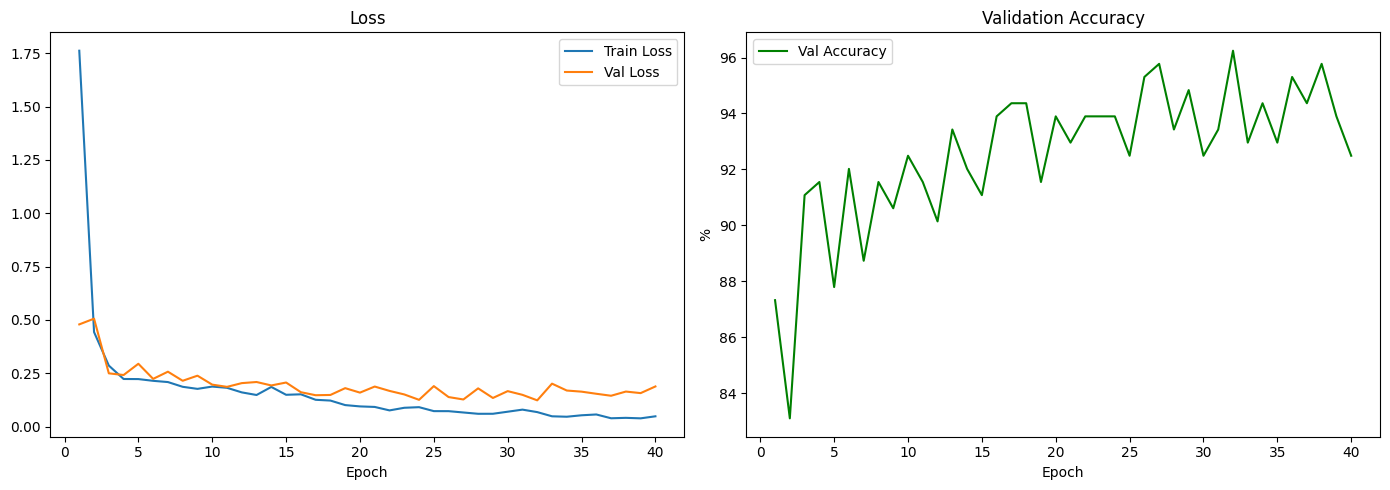

In [15]:
epochs_range = range(1, num_epochs + 1)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

# Loss plot
ax1.plot(epochs_range, history["train_loss"], label="Train Loss")
ax1.plot(epochs_range, history["val_loss"], label="Val Loss")
ax1.set_title("Loss")
ax1.set_xlabel("Epoch")
ax1.legend()

# Accuracy plot
ax2.plot(epochs_range, history["val_acc"], label="Val Accuracy", color="green")
ax2.set_title("Validation Accuracy")
ax2.set_xlabel("Epoch")
ax2.set_ylabel("%")
ax2.legend()

plt.tight_layout()
plt.show()

<div style="background-color: #f0fff0; border:2px solid #ffb703; border-radius:8px; padding:10px; color:black;">

The validation loss is starting to increase after around 30 epochs, even though the training loss continues to decrease. Then, we saved hte best model at epoch 33, which corresponds to the lowest validation loss. The final validation accuracy is around 95%, which indicates that the model is performing well on the validation set.

## Data Augmentation Visualization

We visualized some samples to see the effect of data augmentation and check that the training dataset is not mislabeled.

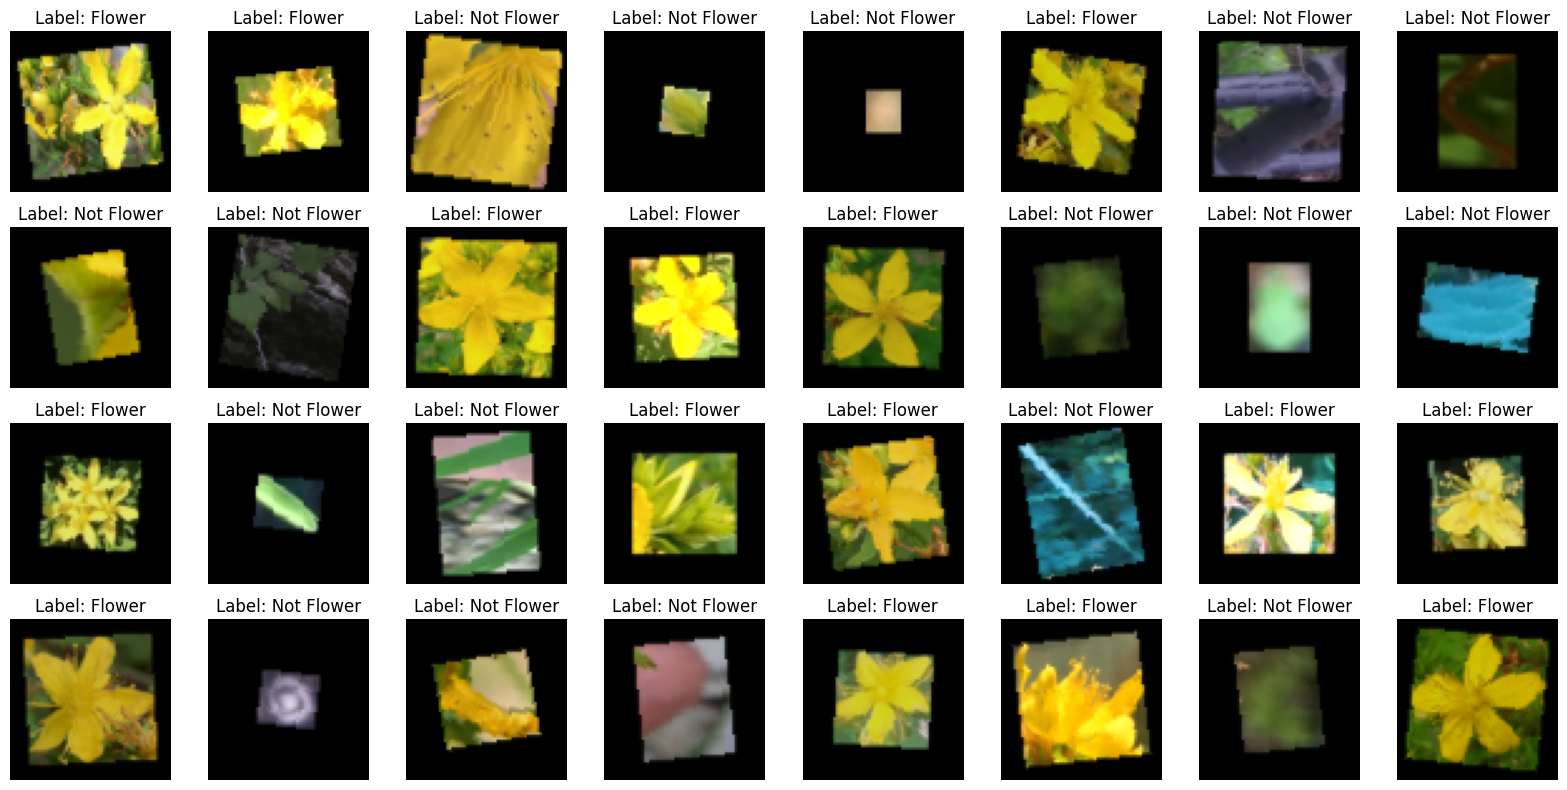

In [16]:
# Visualize random samples from each class to spot bad labels
import random

fig, axes = plt.subplots(4, 8, figsize=(16, 8))
for idx, ax in enumerate(axes.flatten()):
    img, label = train_loader.dataset[random.randint(0, len(train_loader.dataset)-1)]
    img = img.permute(1, 2, 0) * 0.5 + 0.5  # denormalize
    ax.imshow(img)

    if label == 0:
        label_name = "Flower"
    else:
        label_name = "Not Flower"
    ax.set_title(f"Label: {label_name}")
    ax.axis("off")
plt.tight_layout()
plt.show()

# Confusion Matrix Visualization

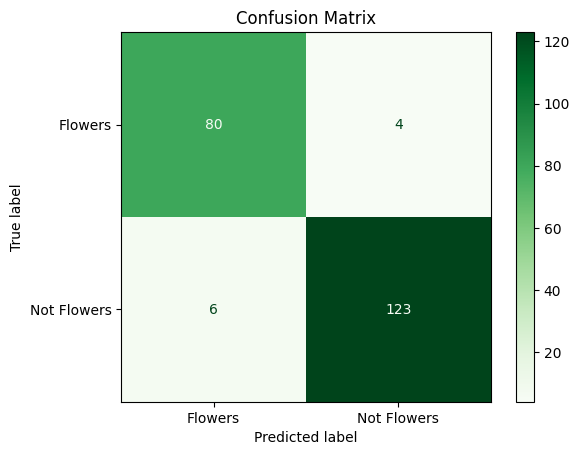

In [17]:
from sklearn.metrics import ConfusionMatrixDisplay

all_preds, all_labels = [], []

model.eval()
with torch.no_grad():
    for images, labels in test_loader:
        images, labels = images.to(device), labels.to(device)
        labels = labels.float().unsqueeze(1)
        outputs = model(images)
        predicted = (outputs >= 0.0).float()
        all_preds.extend(predicted.cpu().numpy())
        all_labels.extend(labels.cpu().numpy())

ConfusionMatrixDisplay.from_predictions(
    all_labels,
    all_preds,
    display_labels=["Flowers", "Not Flowers"],
    cmap="Greens"
)
plt.title("Confusion Matrix")
plt.show()

## Conclusion

We got a good performance on the validation set, with a final accuracy of around 95%. The training process seems to be stable and the model was saved before the overfitting started. The data augmentation gave us more precision and robustness to the model, and the confusion matrix shows that the model is performing well on both classes.

To further improve the model, we should train the model with not only one flowers but others species of flowers. Right now, the model recognize Hypericum perforatum flowers but in the future, we want to be able to recognize other species of flowers.
